# 02 · Thống kê mô tả

Giá, lợi suất log $r_t = \ln(P_t / P_{t-1})$, biến động và thanh khoản của 60 mã (10 ngành) trong khung phân tích chung.
Mã được xếp theo ngành (màu nhãn và vạch phân cách theo ngành); 20 mã vốn hoá lớn của giai đoạn trước được đối chiếu với 40 mã bổ sung.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS = U.SYMBOLS
COL = U.SYMBOL_COLORS

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

## 1. Diễn biến giá (chuẩn hoá về 100 tại ngày đầu khung phân tích)

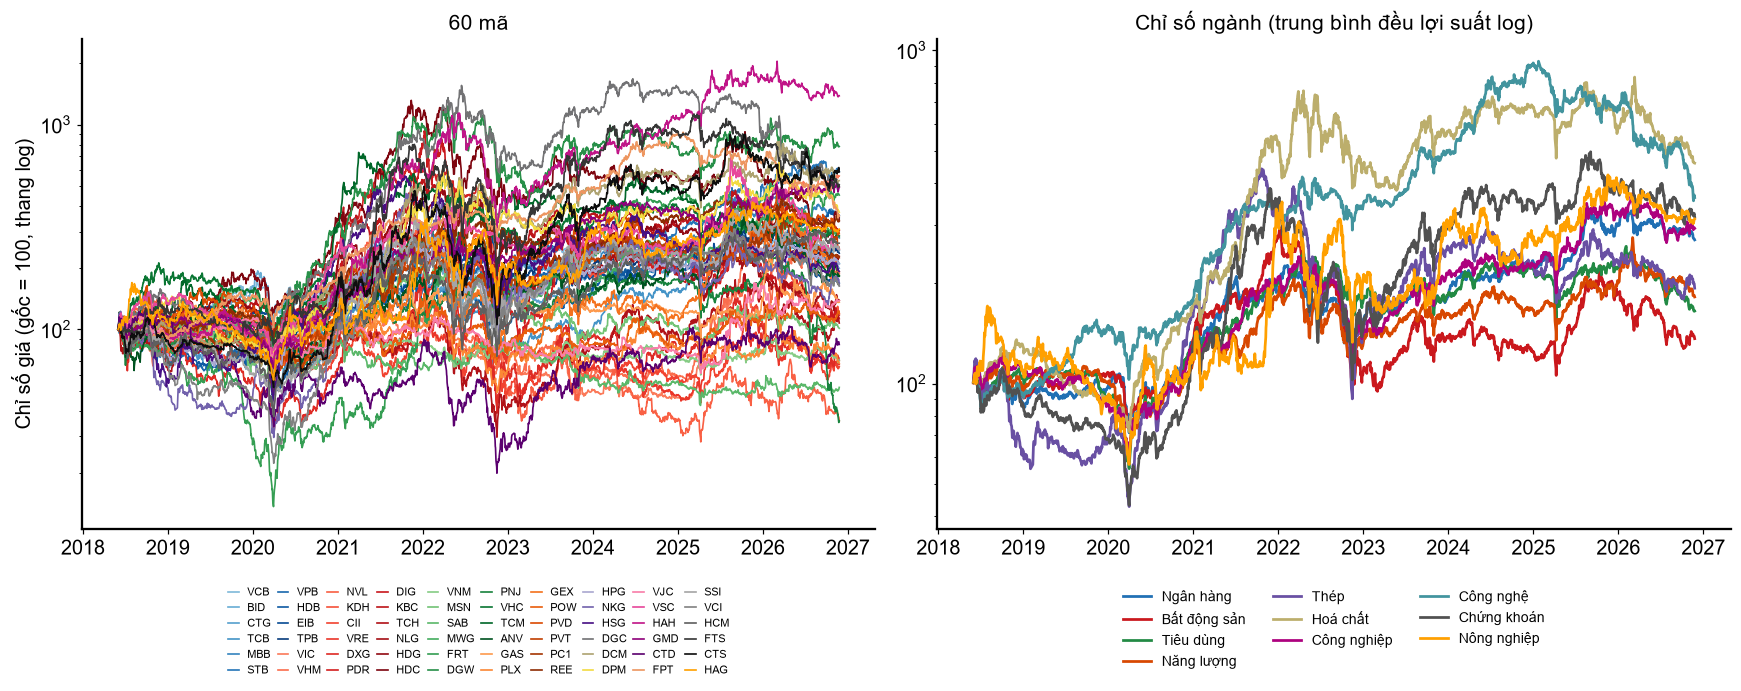

Chỉ số cuối kỳ (gốc 100) — mã:
{'VCB': 209, 'BID': 199, 'CTG': 243, 'TCB': 210, 'MBB': 351, 'STB': 590, 'VPB': 280, 'HDB': 359, 'EIB': 168, 'TPB': 236, 'VIC': 561, 'VHM': 187, 'NVL': 36, 'KDH': 120, 'CII': 66, 'VRE': 67, 'DXG': 70, 'PDR': 113, 'DIG': 117, 'KBC': 305, 'TCH': 107, 'NLG': 139, 'HDG': 228, 'HDC': 339, 'VNM': 71, 'MSN': 101, 'SAB': 52, 'MWG': 284, 'FRT': 453, 'DGW': 783, 'PNJ': 36, 'VHC': 286, 'TCM': 182, 'ANV': 183, 'GAS': 136, 'PLX': 68, 'GEX': 191, 'POW': 120, 'PVD': 294, 'PVT': 248, 'PC1': 224, 'REE': 341, 'HPG': 208, 'NKG': 164, 'HSG': 192, 'DGC': 509, 'DCM': 533, 'DPM': 373, 'VJC': 138, 'VSC': 247, 'HAH': 1385, 'GMD': 493, 'CTD': 84, 'FPT': 358, 'SSI': 245, 'VCI': 163, 'HCM': 264, 'FTS': 501, 'CTS': 588, 'HAG': 309}
Chỉ số cuối kỳ — ngành:
{'Ngân hàng': 270, 'Bất động sản': 136, 'Tiêu dùng': 165, 'Năng lượng': 182, 'Thép': 193, 'Hoá chất': 459, 'Công nghiệp': 292, 'Công nghệ': 362, 'Chứng khoán': 317, 'Nông nghiệp': 312}


In [2]:
px = con.execute("SELECT time, symbol, close FROM v_analysis ORDER BY time").df() \
        .pivot(index="time", columns="symbol", values="close")[SYMBOLS]
rebased = 100 * px / px.bfill().iloc[0]      # TCB thiếu 2 phiên đầu: chuẩn hoá về 100 tại phiên đầu có giá

# chỉ số ngành: trung bình đều lợi suất log các mã trong ngành, cộng dồn
r0 = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS]
sector_idx = pd.DataFrame({sec: 100 * np.exp(r0[[s for s in SYMBOLS if SECTOR[s] == sec]].mean(axis=1).fillna(0).cumsum())
                           for sec in SECTORS})

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for s in SYMBOLS:
    axes[0].plot(rebased.index, rebased[s], color=COL[s], lw=1.1, label=s)
axes[0].set_yscale("log")
axes[0].set_ylabel("Chỉ số giá (gốc = 100, thang log)")
axes[0].set_title(f"{len(SYMBOLS)} mã")
axes[0].legend(ncol=10, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=7, columnspacing=0.6, handlelength=1.0)
for sec in SECTORS:
    axes[1].plot(sector_idx.index, sector_idx[sec], color=(U.PALETTE["teal"] if sec == "Công nghệ" else SC[sec]), lw=1.8, label=sec)  # đổi màu Công nghệ cho khỏi trùng họ xanh lá của Tiêu dùng
axes[1].set_yscale("log")
axes[1].set_title("Chỉ số ngành (trung bình đều lợi suất log)")
axes[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=9)
U.finalize_figure(fig, "02_price_rebased")
plt.show()
print("Chỉ số cuối kỳ (gốc 100) — mã:"); print(rebased.iloc[-1].round(0).astype(int).to_dict())
print("Chỉ số cuối kỳ — ngành:"); print(sector_idx.iloc[-1].round(0).astype(int).to_dict())

## 2. Bảng thống kê mô tả lợi suất log ngày

In [3]:
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS]
desc = r.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"] = r.skew()
desc["excess_kurt"] = r.kurt()
desc["mean_ann"] = r.mean() * 252
desc["vol_ann"] = r.std() * np.sqrt(252)
desc["sharpe_ann (rf=0)"] = desc["mean_ann"] / desc["vol_ann"]
desc.insert(0, "ngành", [SECTOR[s] for s in desc.index])
U.save_table(desc, "02_return_descriptives")
desc[["ngành", "count", "mean_ann", "vol_ann", "sharpe_ann (rf=0)", "skew", "excess_kurt", "1%", "99%", "min", "max"]]

,ngành,count,mean_ann,vol_ann,sharpe_ann (rf=0),skew,excess_kurt,1%,99%,min,max
VCB,Ngân hàng,"2,120.0000",0.0940,0.2606,0.3608,-0.0298,3.3233,-0.0494,0.0483,-0.0725,0.0673
BID,Ngân hàng,"2,120.0000",0.0834,0.3341,0.2498,-0.2348,2.2289,-0.0709,0.0611,-0.0726,0.0680
CTG,Ngân hàng,"2,120.0000",0.1071,0.3283,0.3261,-0.2038,2.3440,-0.0702,0.0602,-0.0728,0.0674
TCB,Ngân hàng,"2,118.0000",0.0804,0.3254,0.2471,-0.2737,2.5731,-0.0711,0.0607,-0.0729,0.0681
MBB,Ngân hàng,"2,120.0000",0.1499,0.3025,0.4954,-0.3438,3.0861,-0.0677,0.0541,-0.0729,0.0678
STB,Ngân hàng,"2,120.0000",0.2109,0.3709,0.5687,-0.0033,1.6337,-0.0707,0.0667,-0.0725,0.0677
VPB,Ngân hàng,"2,120.0000",0.1249,0.3433,0.3638,-0.1372,2.2862,-0.0711,0.0660,-0.0727,0.0693
HDB,Ngân hàng,"2,120.0000",0.1585,0.3183,0.4980,-0.0770,2.3043,-0.0631,0.0637,-0.0731,0.0682
EIB,Ngân hàng,"2,120.0000",0.0620,0.3548,0.1747,0.0813,2.2422,-0.0712,0.0668,-0.0727,0.0677
TPB,Ngân hàng,"2,120.0000",0.1018,0.3219,0.3164,-0.1072,2.5181,-0.0682,0.0614,-0.0740,0.0678


In [4]:
# Đối chiếu: cùng thống kê tính bằng SQL trong DuckDB (truy vấn return_summary) và chênh lệch tối đa với pandas
sql_summary = U.query(con, "return_summary").set_index("symbol").loc[SYMBOLS]
print("Chênh lệch tuyệt đối lớn nhất (SQL − pandas):",
      {k: round(float((sql_summary[k] - desc[k]).abs().max()), 6) for k in ["mean_ann", "vol_ann", "skew", "excess_kurt"]})
sql_summary

Chênh lệch tuyệt đối lớn nhất (SQL − pandas): {'mean_ann': 0.0, 'vol_ann': 0.0, 'skew': 0.0, 'excess_kurt': 0.0}


,n,mean_ann,vol_ann,skew,excess_kurt,q01,q99,min,max
symbol,,,,,,,,,
VCB,2120,0.0940,0.2606,-0.0298,3.3233,-0.0494,0.0483,-0.0725,0.0673
BID,2120,0.0834,0.3341,-0.2348,2.2289,-0.0709,0.0611,-0.0726,0.0680
CTG,2120,0.1071,0.3283,-0.2038,2.3440,-0.0702,0.0602,-0.0728,0.0674
TCB,2118,0.0804,0.3254,-0.2737,2.5731,-0.0711,0.0607,-0.0729,0.0681
MBB,2120,0.1499,0.3025,-0.3438,3.0861,-0.0677,0.0541,-0.0729,0.0678
STB,2120,0.2109,0.3709,-0.0033,1.6337,-0.0707,0.0667,-0.0725,0.0677
VPB,2120,0.1249,0.3433,-0.1372,2.2862,-0.0711,0.0660,-0.0727,0.0693
HDB,2120,0.1585,0.3183,-0.0770,2.3043,-0.0631,0.0637,-0.0731,0.0682
EIB,2120,0.0620,0.3548,0.0813,2.2422,-0.0712,0.0668,-0.0727,0.0677


## 3. Rủi ro sụt giảm (drawdown) và tỷ lệ phiên tăng/giảm

In [5]:
wealth = np.exp(r.cumsum())
drawdown = wealth / wealth.cummax() - 1
risk = pd.DataFrame({
    "ngành": [SECTOR[s] for s in SYMBOLS],
    "max_drawdown": drawdown.min(),
    "ngày đáy": drawdown.idxmin().dt.date,
    "tỷ lệ phiên tăng": (r > 0).mean(),
    "tỷ lệ phiên giảm": (r < 0).mean(),
    "tỷ lệ phiên đứng giá": (r == 0).mean(),
})
U.save_table(risk, "02_drawdown_updown")
risk

,ngành,max_drawdown,ngày đáy,tỷ lệ phiên tăng,tỷ lệ phiên giảm,tỷ lệ phiên đứng giá
VCB,Ngân hàng,-0.3949,2020-03-23,0.4632,0.4533,0.0835
BID,Ngân hàng,-0.4450,2020-03-23,0.4566,0.4759,0.0675
CTG,Ngân hàng,-0.5187,2022-10-11,0.4835,0.4557,0.0608
TCB,Ngân hàng,-0.6434,2022-11-15,0.4679,0.4557,0.0755
MBB,Ngân hàng,-0.5064,2022-11-15,0.4769,0.4377,0.0854
STB,Ngân hàng,-0.5858,2022-10-24,0.4774,0.4552,0.0675
VPB,Ngân hàng,-0.4851,2020-03-31,0.4646,0.4415,0.0939
HDB,Ngân hàng,-0.5994,2020-03-30,0.4717,0.4255,0.1028
EIB,Ngân hàng,-0.5702,2022-11-21,0.4217,0.4575,0.1208
TPB,Ngân hàng,-0.5499,2022-10-11,0.4528,0.4344,0.1127


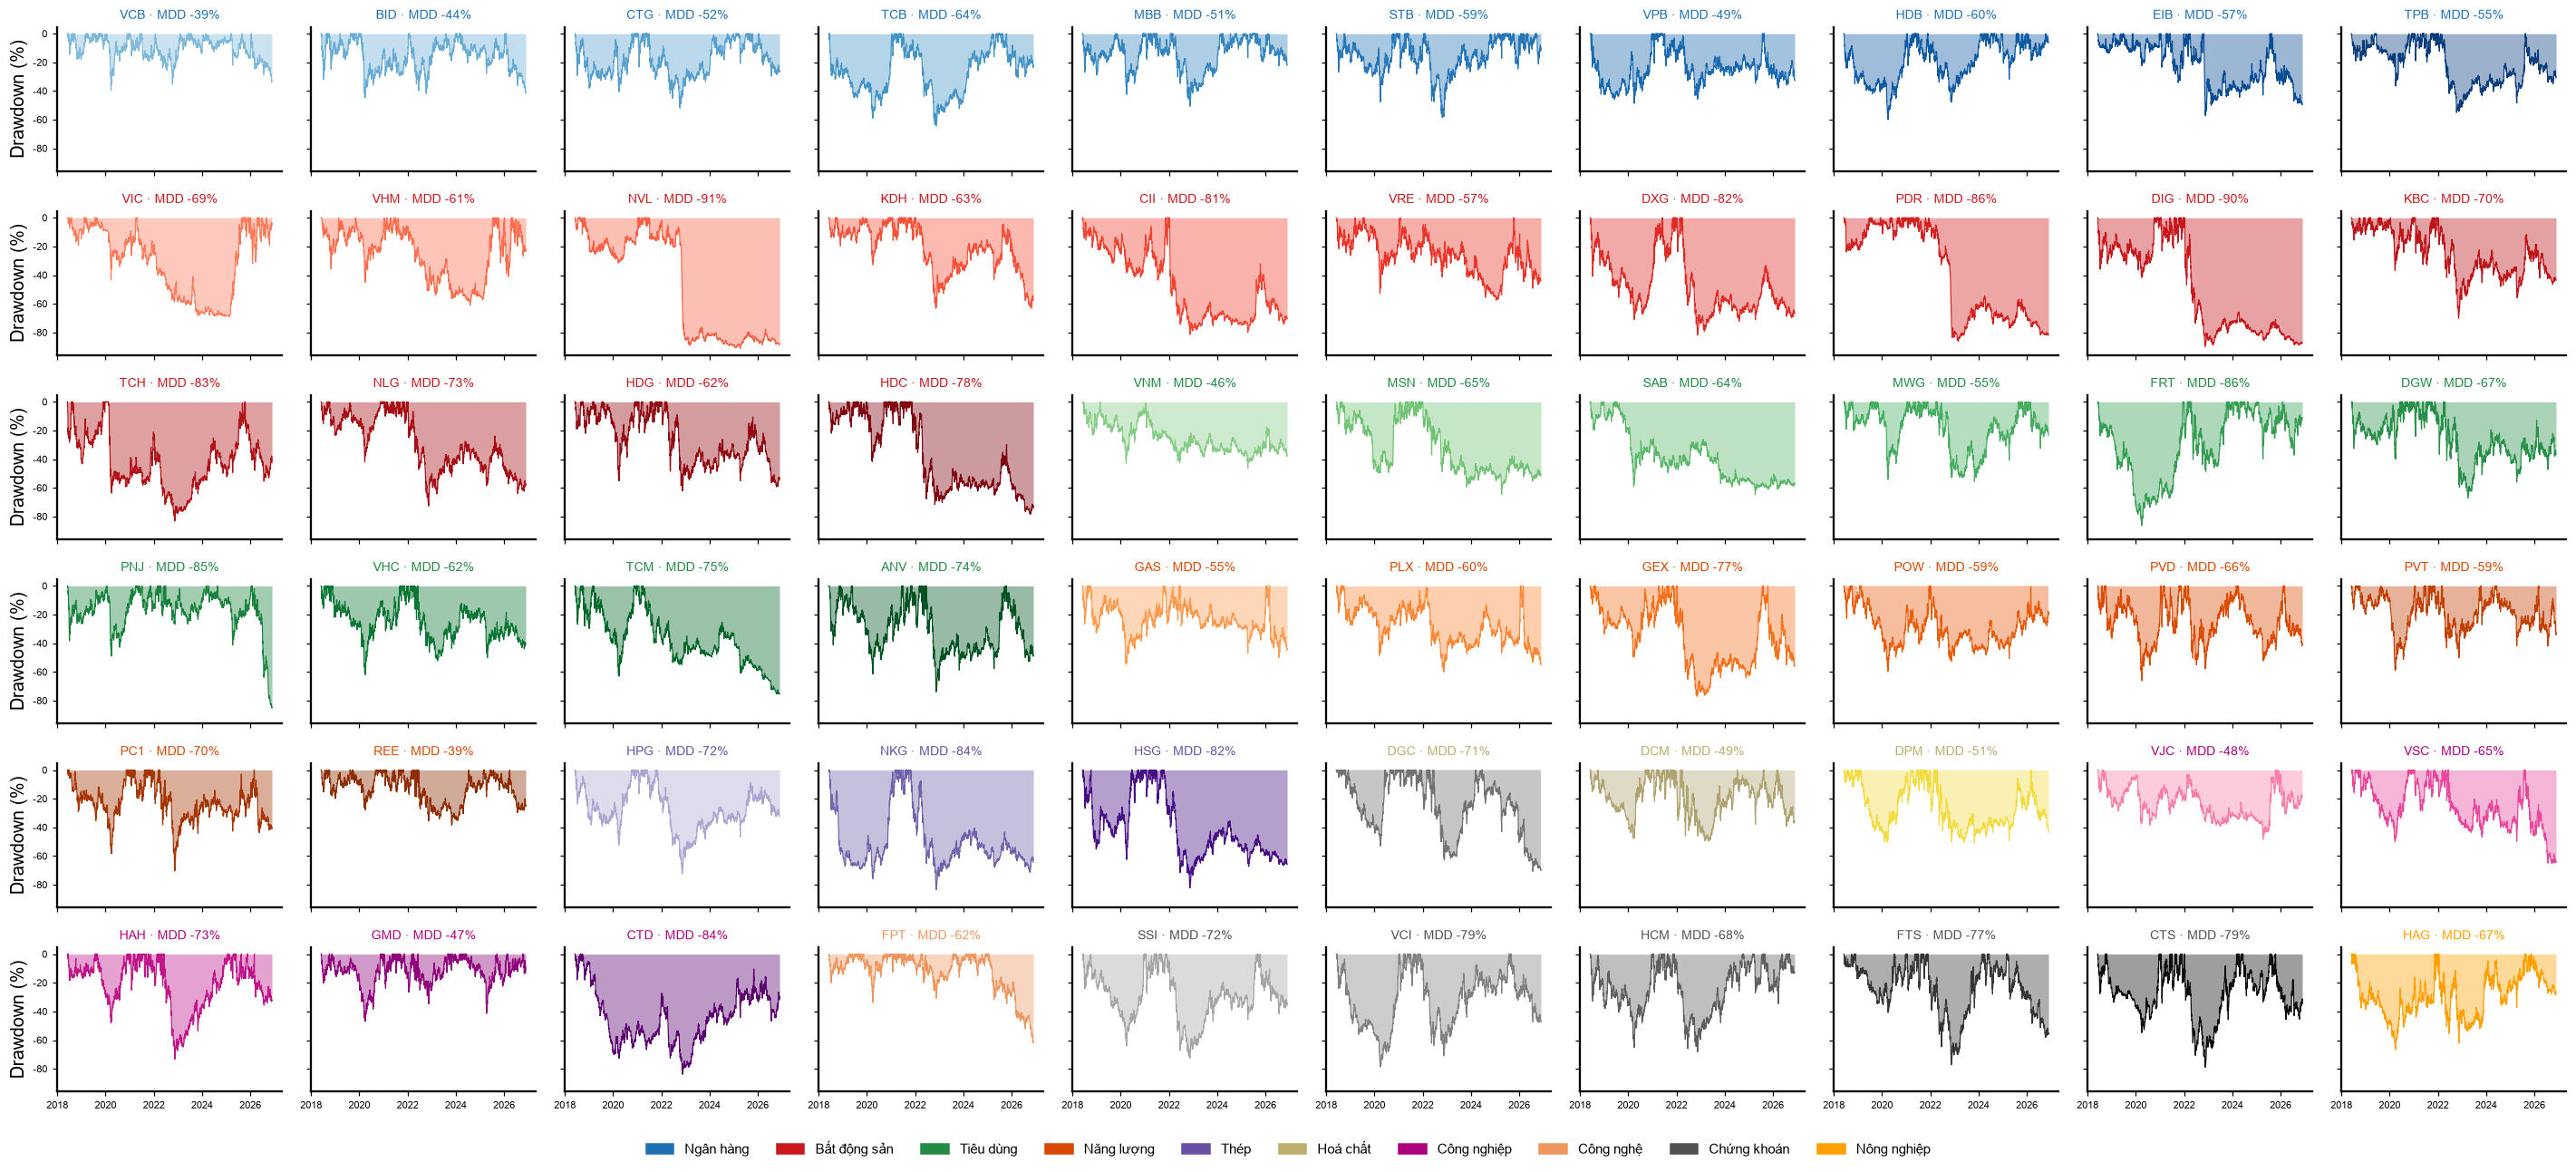

In [6]:
fig, axes = plt.subplots(*U.symbol_grid(), figsize=U.symbol_grid_size(2.6, 1.9), sharex=True, sharey=True)
for ax, s in zip(axes.ravel(), SYMBOLS):
    ax.fill_between(drawdown.index, 100 * drawdown[s], color=COL[s], alpha=0.4, lw=0)
    ax.plot(drawdown.index, 100 * drawdown[s], color=COL[s], lw=0.8)
    ax.set_title(f"{s} · MDD {100 * drawdown[s].min():.0f}%", fontsize=9, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=7); U.year_axis(ax, 2)
for ax in axes[:, 0]: ax.set_ylabel("Drawdown (%)")
sector_legend(fig, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=10, fontsize=10)
U.finalize_figure(fig, "02_drawdown")
plt.show()

## 4. Lợi suất và biến động theo năm

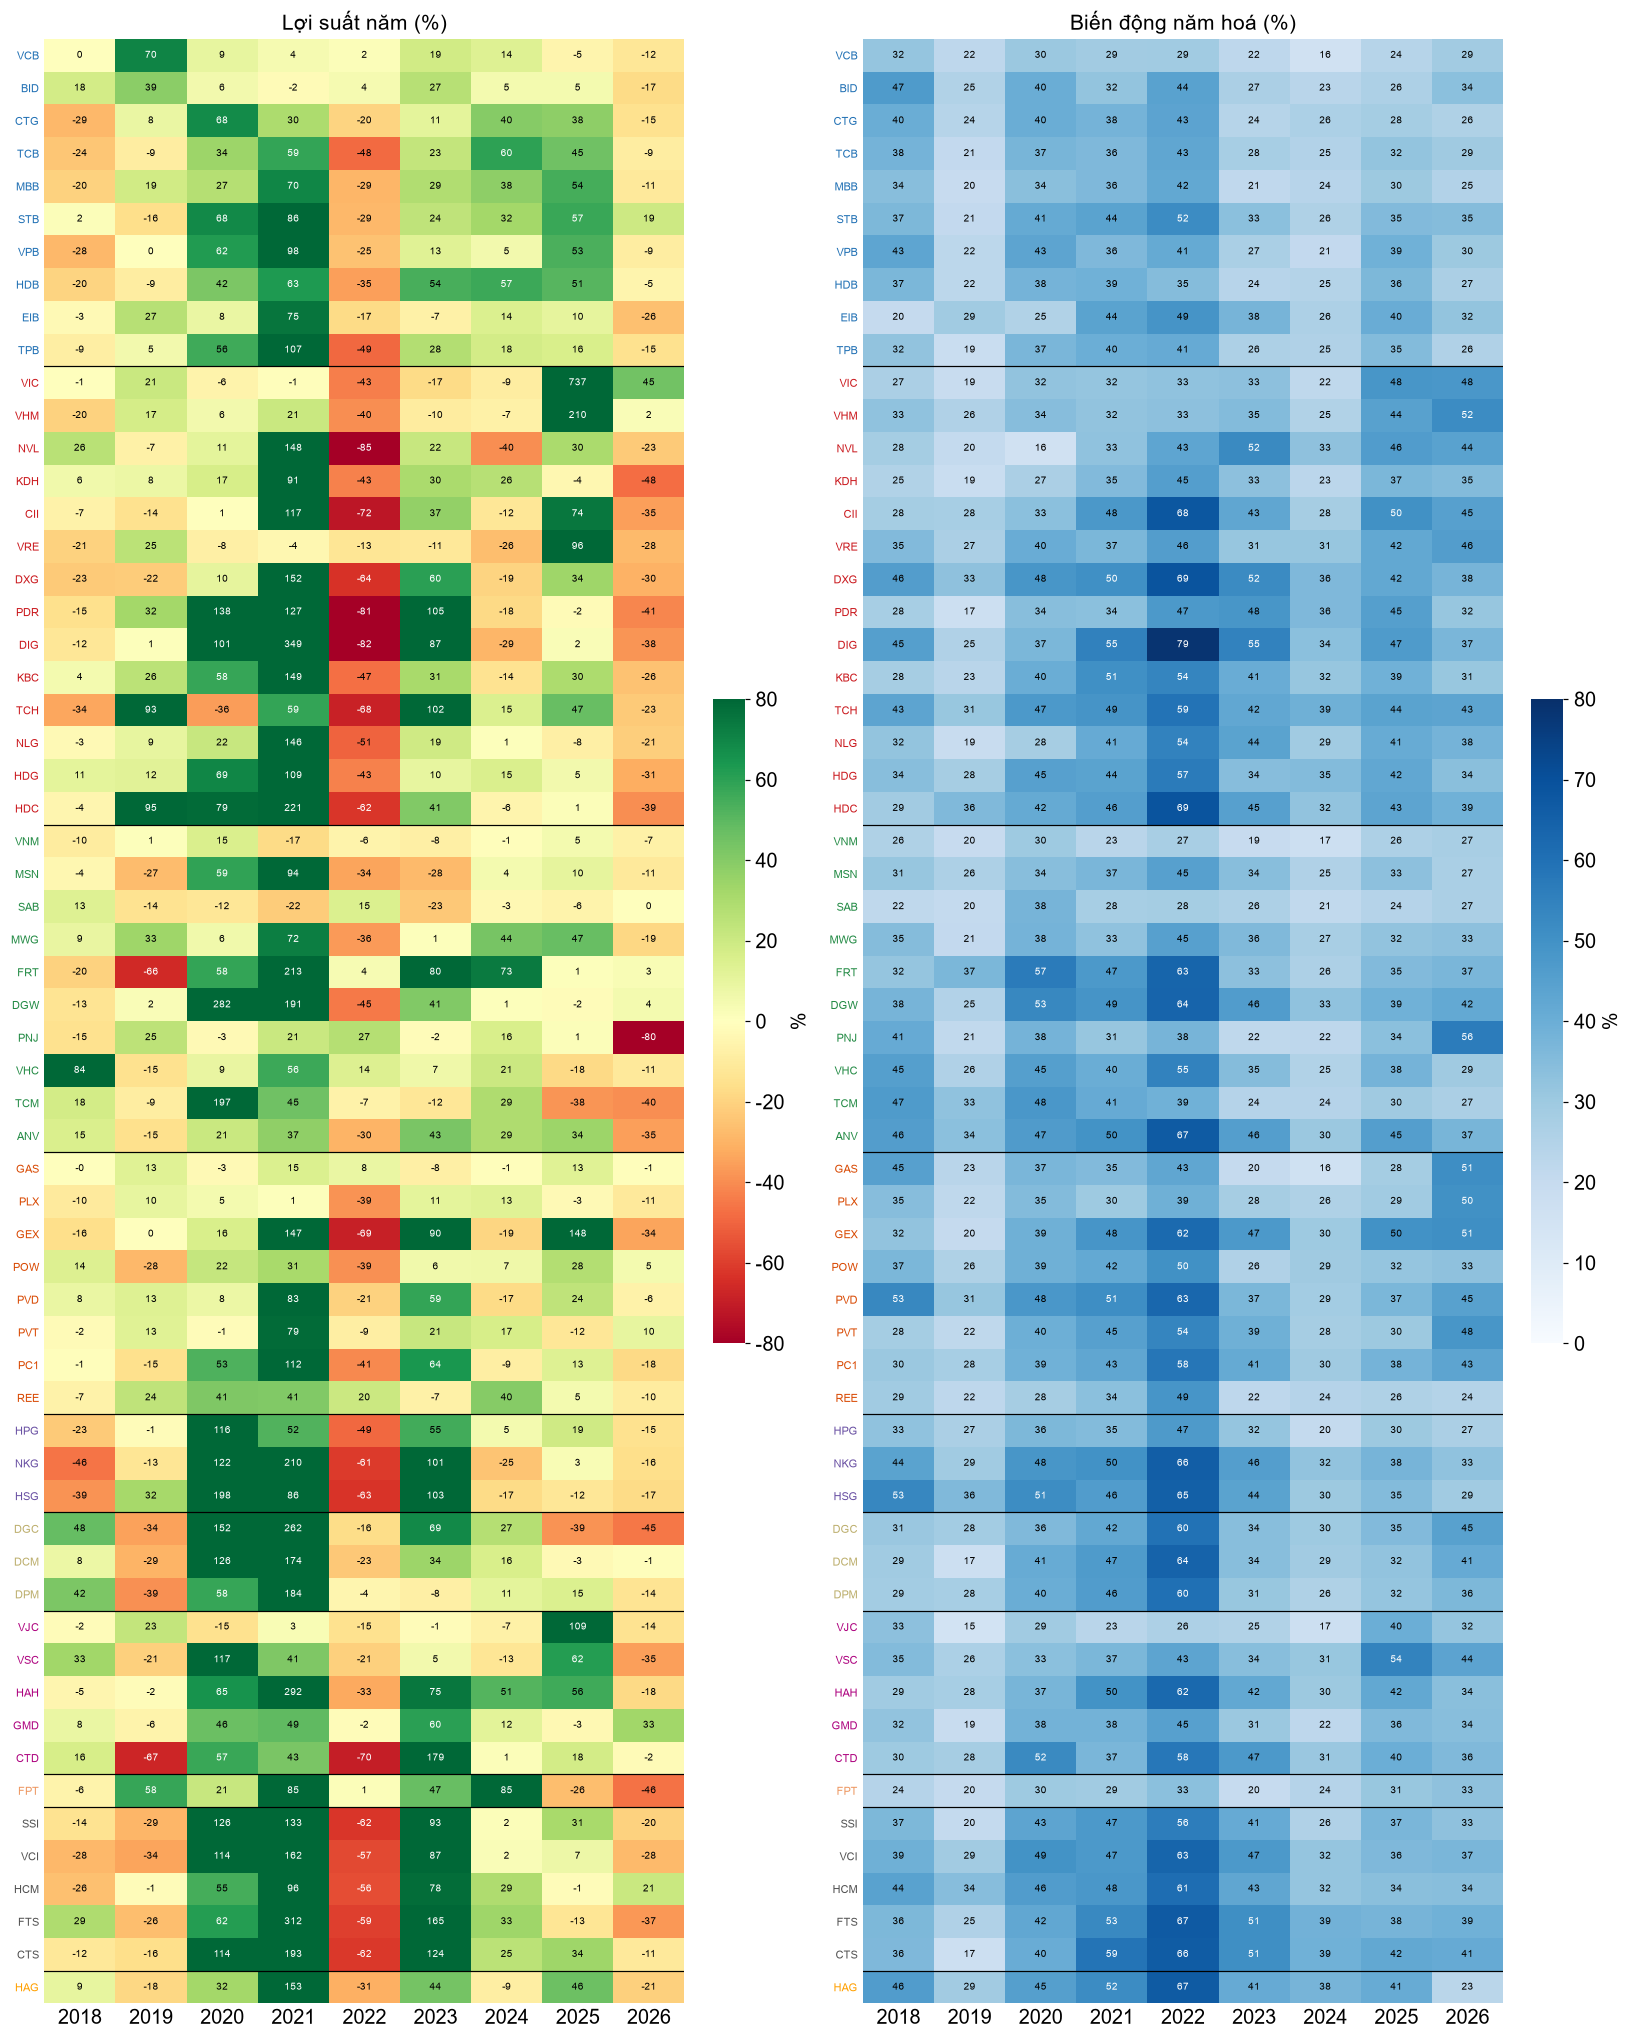

year                           2018     2019     2020     2021     2022  \
lợi suất (%)  Ngân hàng    -11.3000  13.4000  38.0000  58.9000 -24.6000   
              Bất động sản  -6.6000  21.1000  32.9000 120.3000 -56.6000   
              Tiêu dùng      7.6000  -8.5000  63.3000  69.1000  -9.8000   
              Năng lượng    -1.7000   3.8000  17.6000  63.5000 -23.5000   
              Thép         -35.7000   5.9000 145.2000 116.0000 -57.4000   
              Hoá chất      32.6000 -34.2000 112.1000 206.7000 -14.8000   
              Công nghiệp   10.2000 -14.4000  54.2000  85.5000 -28.0000   
              Công nghệ     -6.1000  58.1000  21.3000  84.8000   1.3000   
              Chứng khoán  -10.3000 -21.4000  94.2000 179.2000 -59.3000   
              Nông nghiệp    9.4000 -18.4000  31.9000 153.3000 -31.1000   
biến động (%) Ngân hàng     35.9000  22.5000  36.8000  37.4000  41.9000   
              Bất động sản  32.9000  25.1000  36.1000  41.8000  54.0000   
              Tiêu dùng     36.2000  26.2000  42.7000  37.9000  47.1000   
              Năng lượng    36.2000  24.2000  38.2000  40.9000  52.2000   
              Thép          43.3000  30.5000  45.4000  43.7000  59.4000   
              Hoá chất      29.6000  24.5000  38.9000  45.0000  61.4000   
              Công nghiệp   32.0000  23.3000  38.2000  37.0000  47.0000   
              Công nghệ     24.3000  20.1000  29.9000  29.3000  33.5000   
              Chứng khoán   38.5000  25.3000  44.3000  50.8000  62.8000   
              Nông nghiệp   46.1000  28.8000  45.3000  51.6000  66.8000   

year                           2023     2024     2025     2026  
lợi suất (%)  Ngân hàng     22.0000  28.2000  32.5000 -10.0000  
              Bất động sản  36.1000  -8.9000  89.6000 -24.0000  
              Tiêu dùng      9.8000  21.3000   3.4000 -19.5000  
              Năng lượng    29.5000   3.8000  27.0000  -8.2000  
              Thép          86.5000 -12.2000   3.1000 -16.0000  
              Hoá chất      31.7000  17.8000  -8.9000 -20.1000  
              Công nghiệp   63.5000   8.8000  48.2000  -7.3000  
              Công nghệ     47.1000  85.0000 -26.4000 -46.4000  
              Chứng khoán  109.1000  18.3000  11.4000 -15.2000  
              Nông nghiệp   44.1000  -8.7000  45.6000 -20.8000  
biến động (%) Ngân hàng     27.0000  23.7000  32.6000  29.2000  
              Bất động sản  42.1000  31.1000  43.6000  40.1000  
              Tiêu dùng     32.1000  25.2000  33.7000  34.3000  
              Năng lượng    32.5000  26.5000  33.7000  43.1000  
              Thép          40.4000  27.5000  34.3000  29.5000  
              Hoá chất      33.1000  28.2000  33.1000  40.7000  
              Công nghiệp   35.8000  26.3000  42.4000  35.9000  
              Công nghệ     19.9000  24.1000  31.0000  32.9000  
              Chứng khoán   46.6000  33.3000  37.3000  36.8000  
              Nông nghiệp   41.2000  37.6000  40.7000  23.1000

In [7]:
# Tính trực tiếp trên khung phân tích chung (2018 chỉ từ 01/06, 2026 đến 25/11) để khớp mọi phân tích khác
rl = r.copy(); rl["year"] = rl.index.year
ret_y = np.exp(rl.groupby("year")[SYMBOLS].sum()).T - 1
vol_y = (rl.groupby("year")[SYMBOLS].std() * np.sqrt(252)).T
U.save_table(100 * ret_y, "02_yearly_return_pct"); U.save_table(100 * vol_y, "02_yearly_vol_pct")

fig, axes = plt.subplots(1, 2, figsize=(15, 0.27 * len(SYMBOLS) + 2.5))
for ax, M, kw in [(axes[0], 100 * ret_y, dict(cmap="RdYlGn", vmin=-80, vmax=80, title="Lợi suất năm (%)")),
                  (axes[1], 100 * vol_y, dict(cmap="Blues", vmin=0, vmax=80, title="Biến động năm hoá (%)"))]:
    U.make_heatmap(ax, M, fmt="{:.0f}", cbar_label="%", **kw)
    for t in ax.texts: t.set_fontsize(6.5)
    ax.set_yticks(range(len(SYMBOLS)), SYMBOLS, fontsize=7.5)
    for t, s in zip(ax.get_yticklabels(), SYMBOLS): t.set_color(SC[SECTOR[s]])
    for i in range(1, len(SYMBOLS)):
        if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]: ax.axhline(i - 0.5, color="black", lw=0.8)
U.finalize_figure(fig, "02_yearly_heatmap")
plt.show()

# trung bình theo ngành: lợi suất năm và biến động năm (trung bình đều các mã trong ngành)
sec_y = pd.concat({"lợi suất (%)": 100 * ret_y.groupby(lambda s: SECTOR[s], sort=False).mean(),
                   "biến động (%)": 100 * vol_y.groupby(lambda s: SECTOR[s], sort=False).mean()})
sec_y.round(1)

## 5. Biến động lịch sử 20 phiên (năm hoá)

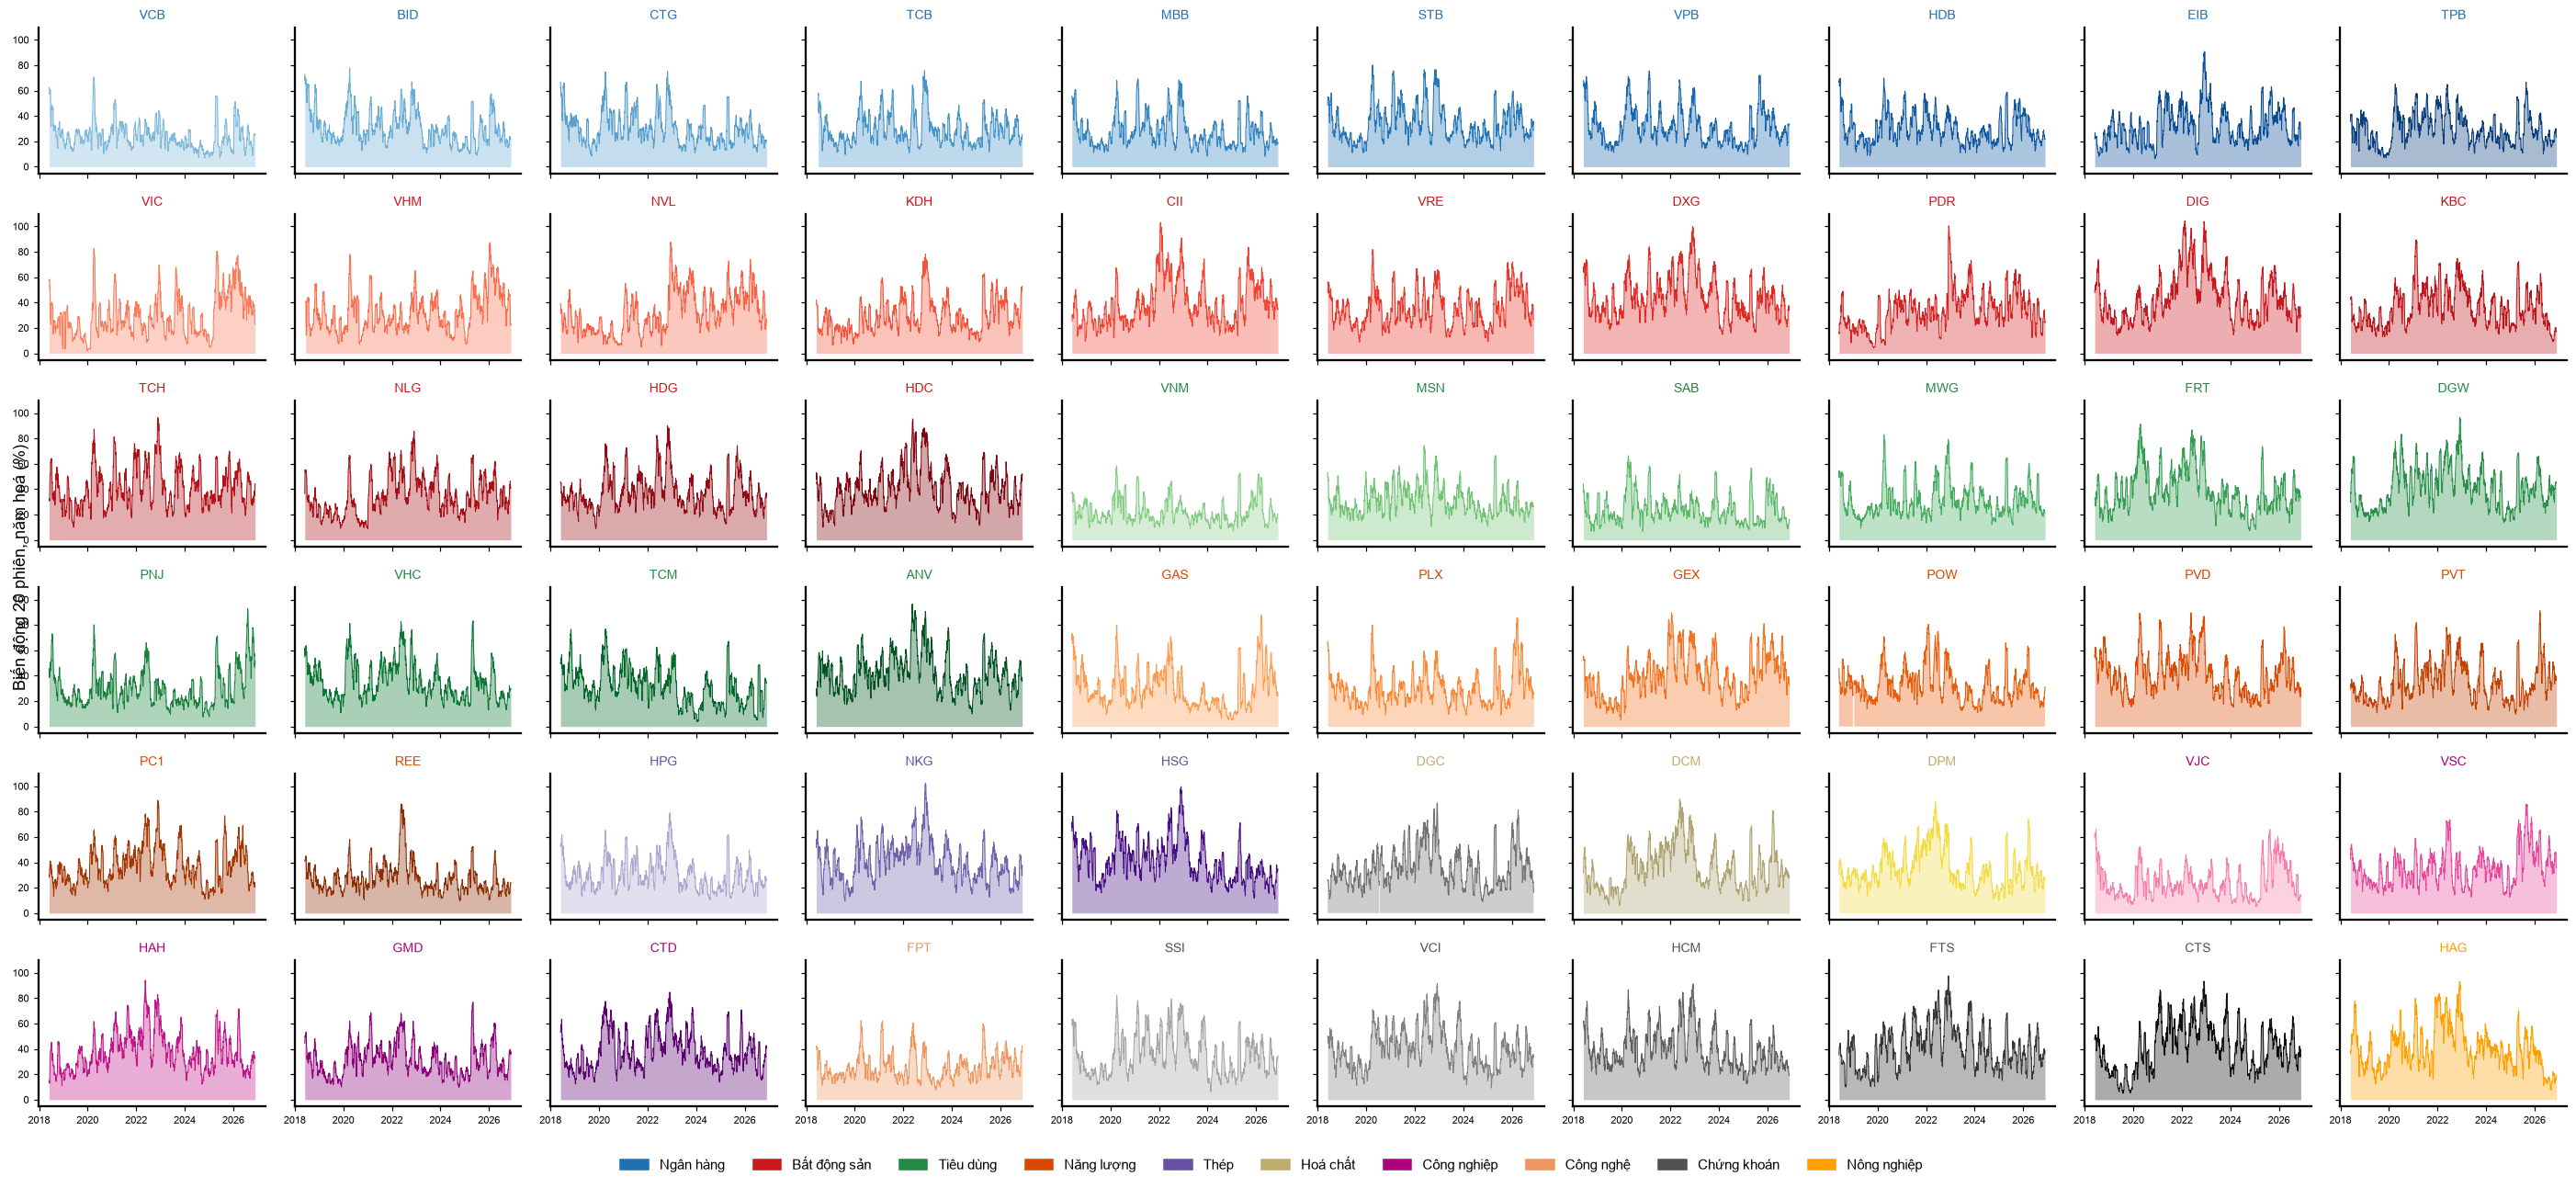

Biến động 20 phiên trung bình 60 mã: đỉnh 68% ngày 07/12/2022; thấp nhất 17% ngày 03/01/2025
Trung bình theo năm (%): {2018: 35.1, 2019: 24.1, 2020: 35.9, 2021: 39.1, 2022: 48.0, 2023: 35.2, 2024: 26.5, 2025: 33.7, 2026: 34.7}


In [8]:
vol = con.execute("SELECT time, symbol, vol_20d * SQRT(252) AS v FROM v_analysis").df() \
         .pivot(index="time", columns="symbol", values="v")[SYMBOLS]

fig, axes = plt.subplots(*U.symbol_grid(), figsize=U.symbol_grid_size(2.6, 1.9), sharex=True, sharey=True)
for ax, s in zip(axes.ravel(), SYMBOLS):
    ax.fill_between(vol.index, 100 * vol[s], color=COL[s], alpha=0.35, lw=0)
    ax.plot(vol.index, 100 * vol[s], color=COL[s], lw=0.7)
    ax.set_title(s, fontsize=9, color=SC[SECTOR[s]])
    ax.tick_params(labelsize=7); U.year_axis(ax, 2)
fig.supylabel("Biến động 20 phiên, năm hoá (%)", fontsize=12)
sector_legend(fig, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=10, fontsize=10)
U.finalize_figure(fig, "02_rolling_volatility")
plt.show()
mv = vol.mean(axis=1)
print(f"Biến động 20 phiên trung bình {len(SYMBOLS)} mã: đỉnh {100*mv.max():.0f}% ngày {mv.idxmax():%d/%m/%Y}; thấp nhất {100*mv.min():.0f}% ngày {mv.idxmin():%d/%m/%Y}")
print("Trung bình theo năm (%):", (100 * mv.groupby(mv.index.year).mean()).round(1).to_dict())

## 6. Phân bố lợi suất theo mã (boxplot) và thanh khoản

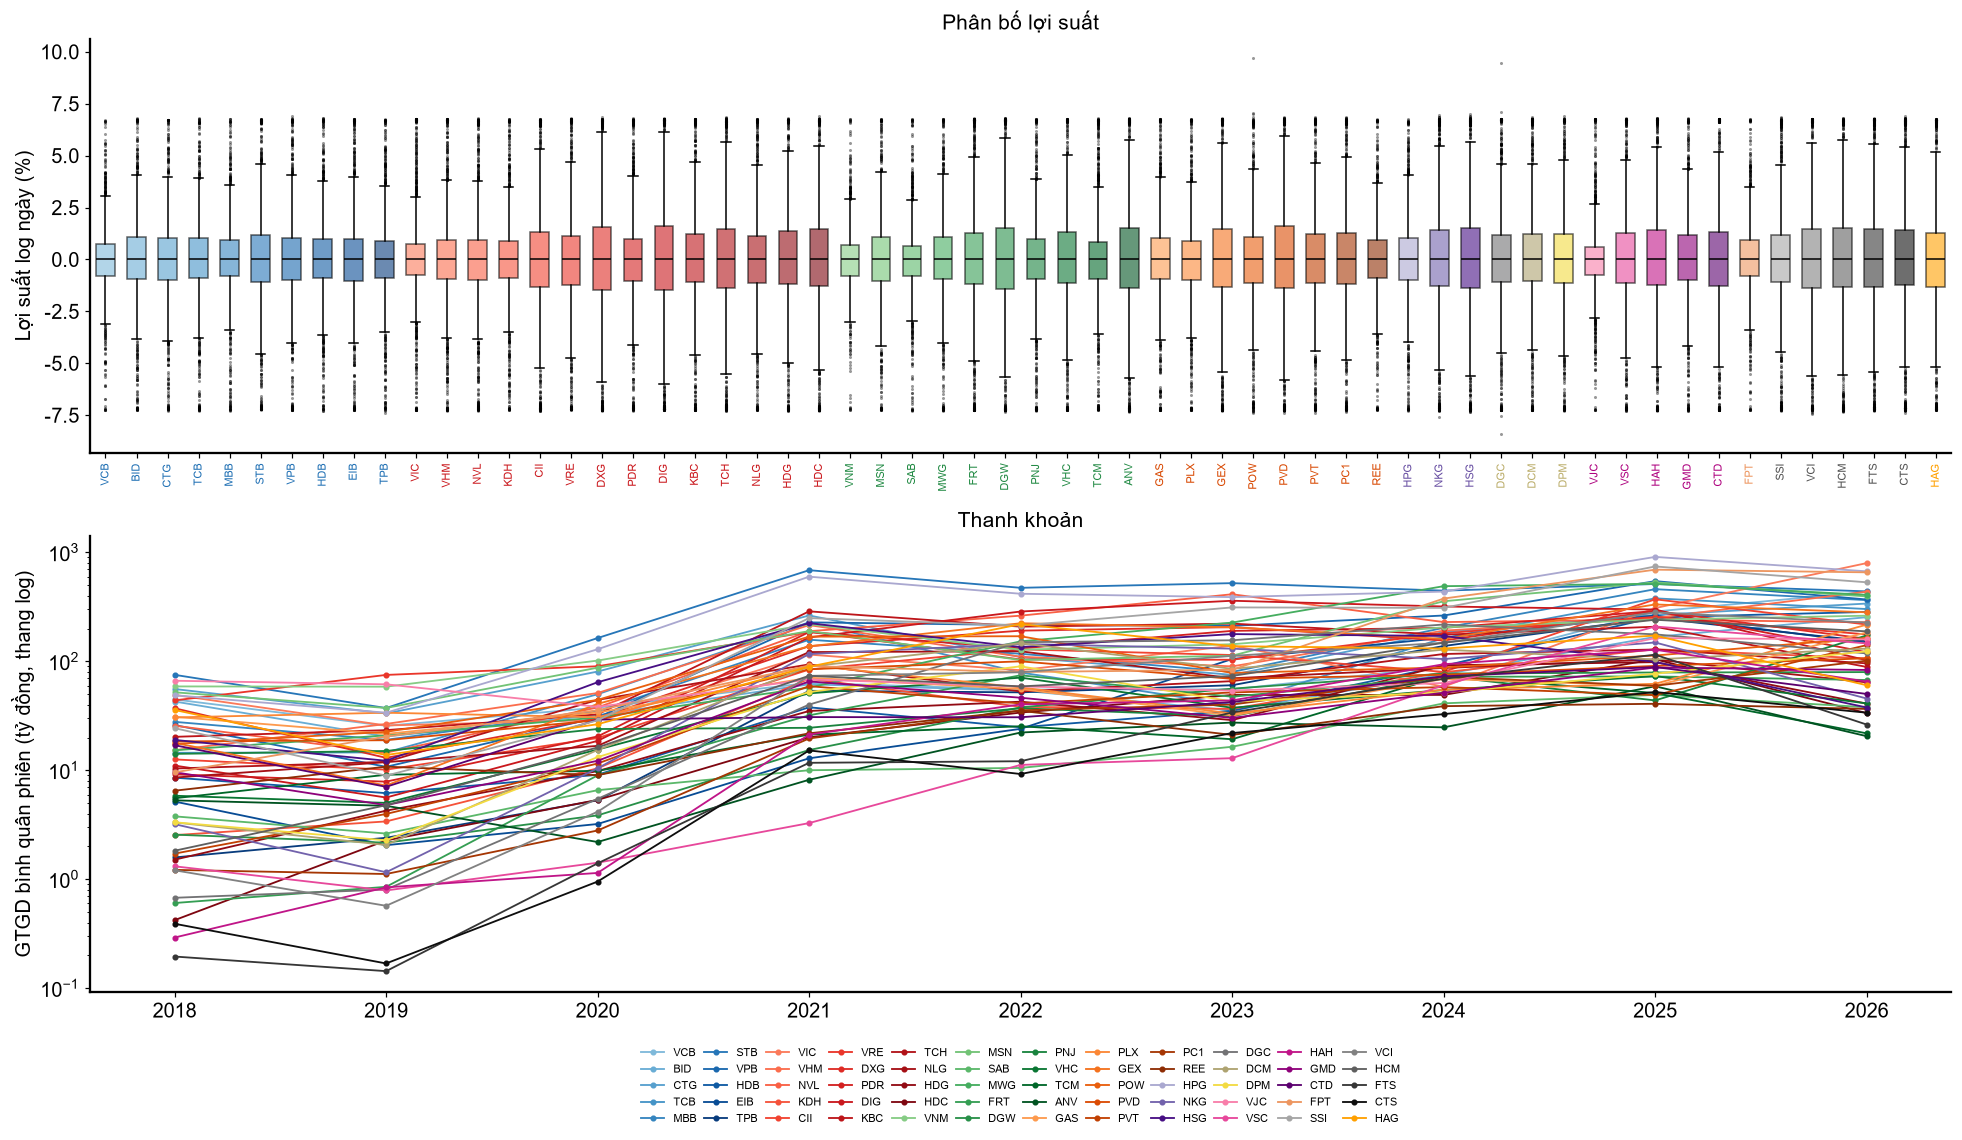

year,ngành,2018,2019,2020,2021,2022,2023,2024,2025,2026
symbol,,,,,,,,,,
VCB,Ngân hàng,45.0000,26.0000,38.0000,64.0000,55.0000,55.0000,89.0000,287.0000,435.0000
BID,Ngân hàng,43.0000,20.0000,32.0000,62.0000,54.0000,36.0000,76.0000,168.0000,255.0000
CTG,Ngân hàng,56.0000,33.0000,81.0000,264.0000,110.0000,75.0000,186.0000,267.0000,340.0000
TCB,Ngân hàng,14.0000,15.0000,50.0000,229.0000,79.0000,40.0000,164.0000,379.0000,303.0000
MBB,Ngân hàng,28.0000,19.0000,35.0000,158.0000,118.0000,80.0000,203.0000,460.0000,365.0000
STB,Ngân hàng,75.0000,37.0000,164.0000,688.0000,474.0000,523.0000,446.0000,514.0000,440.0000
VPB,Ngân hàng,26.0000,11.0000,31.0000,228.0000,216.0000,212.0000,264.0000,546.0000,370.0000
HDB,Ngân hàng,9.0000,6.0000,9.0000,38.0000,25.0000,35.0000,91.0000,254.0000,285.0000
EIB,Ngân hàng,5.0000,2.0000,3.0000,13.0000,24.0000,105.0000,165.0000,264.0000,149.0000


In [9]:
liq = con.execute("""
    SELECT symbol, YEAR(time) AS year, SUM(trade_value) / 1e6 / COUNT(*) AS gtgd_ty
    FROM v_analysis GROUP BY ALL ORDER BY year""").df() \
    .pivot(index="year", columns="symbol", values="gtgd_ty")[SYMBOLS]

fig, axes = plt.subplots(2, 1, figsize=(18, 10.5), gridspec_kw={"height_ratios": [1, 1.1]})
bp = axes[0].boxplot([100 * r[s].dropna() for s in SYMBOLS], tick_labels=SYMBOLS, patch_artist=True,
                     widths=0.6, flierprops=dict(marker=".", markersize=2, alpha=0.4),
                     medianprops=dict(color="black"))
for patch, s in zip(bp["boxes"], SYMBOLS):
    patch.set_facecolor(COL[s]); patch.set_alpha(0.6)
axes[0].tick_params(axis="x", labelsize=7.5, rotation=90)
for t, s in zip(axes[0].get_xticklabels(), SYMBOLS): t.set_color(SC[SECTOR[s]])
axes[0].set_ylabel("Lợi suất log ngày (%)")
axes[0].set_title("Phân bố lợi suất")
for s in SYMBOLS:
    axes[1].plot(liq.index, liq[s], marker="o", ms=3, color=COL[s], lw=1.2, label=s)
axes[1].set_yscale("log")
axes[1].set_ylabel("GTGD bình quân phiên (tỷ đồng, thang log)")
axes[1].set_title("Thanh khoản")
axes[1].legend(ncol=12, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), columnspacing=0.6)
U.finalize_figure(fig, "02_box_liquidity")
plt.show()
U.save_table(liq.T, "02_liquidity_by_year")
liq_t = liq.T.round(0); liq_t.insert(0, "ngành", [SECTOR[s] for s in liq_t.index]); liq_t

## 7. Nhận xét

(Số liệu khung 01/06/2018 – 25/11/2026: 2.111–2.120 phiên mỗi mã; 2.103 phiên chung khi cần ma trận đủ 60 mã — thiếu 2 phiên đầu của TCB,
9 phiên của POW và 6 phiên của DGC quanh thời điểm chuyển sàn.)

- **Lợi suất – rủi ro:** lợi suất log năm hoá cao nhất ở HAH (~31,2%, Sharpe 0,76), DGW (24,6%), STB và CTS (21,1%); âm ở NVL (−12,1%), PNJ (−12,0%),
  SAB (−7,5%), CII (−5,0%). Biến động năm hoá 24–49%: thấp nhất VNM (24,2%), VCB (26,1%), SAB (26,6%); cao nhất DIG (48,6%), DXG (47,4%), CTS (46,1%).
  Trung bình theo ngành: hoá chất +18,6%/năm, công nghệ +15,3%, chứng khoán +13,7%, nông nghiệp +13,5%, công nghiệp +12,7%, ngân hàng +11,7%; thấp nhất bất động sản +3,7%.
  Chứng khoán (43,5%) và bất động sản (40,1%) biến động mạnh nhất, ngân hàng (32,6%) và công nghệ (27,8%) thấp nhất.
- **20 mã cũ so với 40 mã bổ sung:** nhóm bổ sung biến động hơn (40,2% so với 32,6%), sụt giảm sâu hơn (MDD trung bình −70% so với −60%) và lợi suất trung bình cao hơn
  (9,6% so với 7,0%), nhưng **độ nhọn thấp hơn** (1,45 so với 2,54): mã vốn hoá lớn ít biến động thường ngày nhưng thỉnh thoảng có cú sốc lớn, mã nhỏ hơn
  dao động rộng và thường xuyên hơn (nhiều phiên chạm biên độ ±7%).
- **Sụt giảm:** NVL −91,2% (đáy 09/04/2025), DIG −89,7% (15/11/2022), FRT −86,4% (30/03/2020), PDR −86,1%, PNJ −85,1% (đáy 23/11/2026, đang giảm ở cuối mẫu);
  nhẹ nhất REE (−38,6%), VCB (−39,5%), BID (−44,5%). **18/60 mã chạm đáy cùng ngày 15/11/2022**, thêm 12 mã trong 23–31/03/2020 (COVID) và 4 mã ngày 09/04/2025
  → bằng chứng sơ bộ của nhân tố thị trường chung.
- **Theo năm:** 2021 tăng mạnh ở mọi ngành (hoá chất +207%, chứng khoán +179%, nông nghiệp +153%, bất động sản +120%); 2022 là năm sập (chứng khoán −59%,
  bất động sản và thép −57%, ngân hàng −25%); 2020 thép +145%, hoá chất +112%; 2026 (đến 25/11) mọi ngành đều giảm (công nghệ −46%, bất động sản −24%).
  Biến động 20 phiên trung bình của 60 mã đạt đỉnh 68% ngày 07/12/2022 (sau đợt sập tháng 11/2022), thấp nhất 17% ngày 03/01/2025; trung bình năm từ 24% (2019) tới 48% (2022)
  — các đợt biến động cao trùng nhau giữa các mã.
- **Hình dạng:** trung vị lợi suất ngày bằng 0; 4,9–12,5% số phiên đứng giá (thấp nhất HCM, cao nhất KDH, TCM, EIB); độ nhọn vượt chuẩn dương ở cả 60 mã, từ 0,44 (DXG)
  tới 4,27 (VJC), cao nhất ở các mã vốn hoá lớn VJC, SAB, VNM, VCB, MBB (3,1–4,3); độ lệch gần 0 (−0,34 ở MBB đến +0,53 ở VJC).
- **Thanh khoản:** khác biệt rất lớn: năm 2025 GTGD bình quân phiên từ ~41 tỷ (REE), 44 tỷ (PNJ), 49 tỷ (PVT) tới 696 tỷ (FPT), 744 tỷ (SSI), 911 tỷ (HPG); 2026 cao nhất VIC (~799 tỷ).
- **Biến động thay đổi theo thời gian:** biến động trượt dao động mạnh theo cụm và đồng thời ở mọi mã (lưới 6 × 10) → mô hình hoá biến động có điều kiện (GARCH) trước phân tích đuôi.
- **Lưu ý dữ liệu:** chuỗi giá PNJ của nguồn VCI giảm liên tục về cuối mẫu (−85% từ đỉnh) mà không có phiên nào vượt biên độ; chưa đối chiếu được với nguồn khác.